# STEP 1 - Data Generation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.loader import *

Loading satellites/
Aspect ratio:  5
Ratio of rotational diffusion:  0.06769699908603415
Ratio of orthogonal diffusion:  0.7664558871581453


# Load Data

In [2]:
sim = ABPsim('satellites/')
data = sim.get_data()
t = data[:, 0]
x_data = data[:, 2::3].T - sim.domain_size_x
y_data = data[:, 3::3].T - sim.domain_size_y / 2
phi_data = data[:, 4::3].T
rod_size = sim.satellites_xy[-2]
dx = np.cos(phi_data) * rod_size
dy = np.sin(phi_data) * rod_size
x_data = x_data + dx
y_data = y_data + dy

Loading satellites/


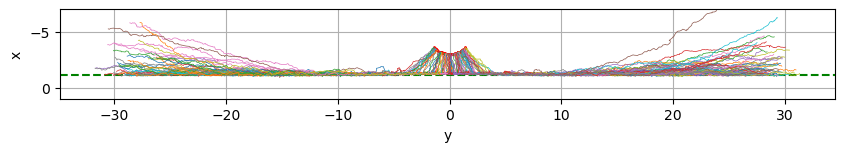

In [10]:


def plot_trajectory(x, y, phi):
    plt.figure(figsize=(10, 10))
    plt.plot(y.T[0], x.T[0], 'ro', ms=1)
    plt.axhline(-2**(1/6), color='g', linestyle='--')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid()
    plt.ylim(None, 0)

    tangent_length = 0.5
    n_steps = x.shape[0]
    #for i in range(0, n_steps, 10):
    #    plt.plot([y[i], y[i] + tangent_length*np.sin(phi[i])],
    #             [x[i], x[i] + tangent_length*np.cos(phi[i])],
    #             'b', alpha=0.5, linewidth=0.8)

    plt.plot(y.T, x.T, lw=0.5)
    plt.xlabel('y')
    plt.ylabel('x')
    plt.gca().invert_yaxis()



phi0 = phi_data[:, 0]
np.random.seed(12345)
sel = -1
plot_trajectory(x_data[:sel,:], y_data[:sel,:], phi_data[:sel,:])
plt.ylim(-7, 1)
plt.gca().invert_yaxis()
plt.savefig('step_1_trajectories.png', dpi=600)
plt.show()

# Pickle everything

In [4]:
payload = dict(
    ALPHAS=ALPHAS,
    n_trajectories=n_trajectories,
    n_steps=n_steps,
    dt=dt,
    X0=X0,
    Y0=Y0,
    PHI0=PHI0,
    PE=PE,
    DT=DT,
    DR=DR,
    FORCE_STRENGTH=FORCE_STRENGTH,
    x_data=x_data,
    y_data=y_data,
    phi_data=phi_data,
    Q2=Q2,
)
np.savez('../GLOBAL/data.npz', **payload)